# 01 · Datos fabricados: fotos con ajustes de color conocidos

## Qué vas a aprender

- Por qué a veces conviene **fabricar** los datos de entrenamiento, y por qué así las etiquetas salen gratis y exactas.
- Los cinco ajustes de color del extra: qué hace cada uno, su rango y su fórmula.
- Cómo se reparten las fotos en *train*, *val* y *test* con una semilla, para que el resultado se pueda repetir.
- Cómo comprobar que las etiquetas fabricadas valen (aplicar el JSON a la original reproduce la editada).

**Dónde estamos.** Queremos que un LLM de visión (un modelo que mira una foto y escribe texto) **lea el estilo de color** de una foto y lo escriba como un JSON de ajustes, por ejemplo `{"exposicion": 0.3, "temperatura": -0.5, ...}`. Con ese JSON se podría **copiar el estilo** a otra foto. Para entrenar y medir a ese modelo necesitamos muchas fotos *con su respuesta correcta*. Este notebook las fabrica.

Este notebook deja en la carpeta de trabajo la carpeta `parejas/` con las fotos originales, las editadas y el archivo `parejas.jsonl`.

## 1. ¿Por qué fabricar los datos?

Para enseñar a un modelo a leer el estilo hacen falta parejas **(foto, ajustes que se le aplicaron)**. Hay dos formas de conseguirlas:

- **A mano.** Alguien mira una foto y apunta «temperatura −0,4». Es lento y poco preciso: dos personas darían números distintos.
- **Fabricándolas.** Cogemos fotos normales, les aplicamos ajustes **aleatorios que nosotros mismos elegimos** y guardamos la pareja (foto editada, JSON de ajustes). Como los ajustes los pusimos nosotros, **conocemos la respuesta exacta**: la etiqueta es gratis y no tiene error.

Es parecido al *aumento de datos* (aplicar giros o cambios de brillo para tener más fotos), pero aquí la edición **es** la etiqueta.

**Una limitación que conviene tener presente.** El modelo verá la foto editada, **no la original**. Tiene que adivinar los ajustes a partir de lo que «suele» tener una foto normal; por eso nunca acertará del todo (un gato naranja *parece* cálido aunque nadie lo haya tocado). Además, algunas ediciones se pueden confundir entre sí (subir la exposición y subir el contraste aclaran las luces) y otras destruyen información (con saturación 0 la foto queda en grises y ya no hay forma de saber qué temperatura tenía). La etiqueta es exacta, pero la tarea no es fácil.

**Las fotos.** Usamos *Oxford-IIIT Pet* (Parkhi, Vedaldi, Zisserman y Jawahar, «Cats and Dogs», CVPR 2012), con licencia **CC BY-SA 4.0**. Mitad gatos y mitad perros, recortadas al centro en cuadrado y reducidas a `RESOLUCION` píxeles de lado.

## 2. Los cinco ajustes de color

Elegimos cinco ajustes sencillos, que cualquiera reconoce en un editor de fotos y que se programan en pocas líneas de `numpy`. Se aplican **en este orden** sobre los valores RGB de la foto (de 0 a 1). La definición exacta está en `estilo/ajustes.py`.

| Ajuste | Qué hace en la foto | Rango | Neutro (no cambia nada) | Fórmula |
|---|---|---|---|---|
| `exposicion` (e) | Aclara u oscurece toda la foto, en pasos de diafragma | −0,7 a 0,7 | 0 | `x = x · 2^e` |
| `temperatura` (t) | Más cálida (naranja) si es positiva, más fría (azul) si es negativa | −1 a 1 | 0 | `R = R·(1+0,25t)`, `B = B·(1−0,25t)` |
| `tinte` (g) | Más magenta si es positivo, más verde si es negativo | −1 a 1 | 0 | `G = G·(1−0,20g)` |
| `contraste` (c) | Separa las luces de las sombras (mayor que 1) o las acerca al gris (menor que 1) | 0,6 a 1,5 | 1 | `x = (x−0,5)·c + 0,5` |
| `saturacion` (s) | Intensidad del color; 0 es blanco y negro | 0,2 a 1,8 | 1 | `Y = 0,299R + 0,587G + 0,114B`; `x = Y + (x−Y)·s` |

Al final se recorta todo a [0, 1] (un píxel no puede ser más blanco que el blanco). Los valores se sortean de forma **uniforme** dentro de su rango y se redondean a 2 decimales.

La celda de parámetros fija también la `SEMILLA`: el número con el que arranca el sorteo. Con la misma semilla salen **siempre** los mismos ajustes y el mismo reparto.

In [1]:
# Parámetros (papermill). Valores pequeños por defecto, pensados para CI;
# en clase o en local se suben con variables de entorno ESTILO_*.
import os
N_EJEMPLOS = int(os.environ.get("ESTILO_N_EJEMPLOS", "60"))   # fotos = parejas
EPOCAS = int(os.environ.get("ESTILO_EPOCAS", "2"))
RESOLUCION = int(os.environ.get("ESTILO_RESOLUCION", "224"))  # lado de las fotos en píxeles
MODELO = os.environ.get("ESTILO_MODELO", "HuggingFaceTB/SmolVLM-256M-Instruct")
CARPETA_TRABAJO = os.environ.get("ESTILO_TRABAJO", "_trabajo")
SEMILLA = 2012

In [2]:
import json, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Localizar la carpeta del extra (la que contiene `estilo/`), desde donde se ejecute el notebook
raiz = Path(os.environ.get('ESTILO_EXTRA') or next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'estilo').is_dir()))
sys.path.insert(0, str(raiz))
import estilo as es

plt.rcParams['figure.dpi'] = 55   # figuras ligeras dentro del notebook
trabajo = es.carpeta_trabajo(CARPETA_TRABAJO)
print('Parámetros:', dict(N_EJEMPLOS=N_EJEMPLOS, RESOLUCION=RESOLUCION, SEMILLA=SEMILLA))

Parámetros: {'N_EJEMPLOS': 300, 'RESOLUCION': 224, 'SEMILLA': 2012}


## 3. Las fotos y el efecto de cada ajuste

`preparar_fotos` extrae del archivo de Oxford-IIIT Pet las fotos que pedimos (mitad gatos, mitad perros) y las deja recortadas en la carpeta de trabajo. Si no tienes el archivo `images.tar.gz` (791,9 MB), lo descarga de la web oficial; si ya lo tienes, indica su ruta en la variable de entorno `ESTILO_TAR` y no se descarga nada.

Después tomamos la primera foto y aplicamos **un ajuste cada vez** (los demás en neutro) con tres valores: el mínimo de su rango, el neutro y el máximo. Cada fila es un ajuste.

**Qué debes ver:** la columna central es siempre la foto sin tocar. A los lados, el efecto del ajuste: la exposición aclara u oscurece, la temperatura vira entre azul y naranja, el tinte entre verde y magenta, el contraste endurece o suaviza y la saturación va del casi gris al color intenso. La figura se guarda en `img/`.

300 fotos de 224 px; 150 gatos


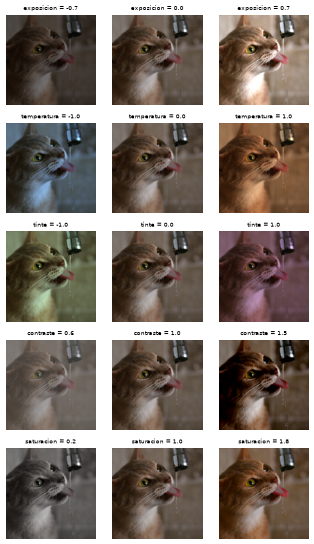

In [3]:
fotos = es.preparar_fotos(trabajo, N_EJEMPLOS, RESOLUCION)
n_gatos = sum(f.name.startswith('gato') for f in fotos)
print(len(fotos), 'fotos de', RESOLUCION, 'px;', n_gatos, 'gatos')

foto = Image.open(fotos[0]).convert('RGB')
fig, ejes = plt.subplots(len(es.NOMBRES), 3, figsize=(6, 10))
for fila, k in enumerate(es.NOMBRES):
    lo, hi, neutro = es.AJUSTES[k]
    for col, v in enumerate([lo, neutro, hi]):
        p = dict(es.NEUTRO, **{k: v})
        ejes[fila, col].imshow(es.aplicar_ajustes(foto, p))
        ejes[fila, col].axis('off')
        ejes[fila, col].set_title(f'{k} = {v}', fontsize=8)
plt.tight_layout()
es.guardar_figura(raiz / 'img' / '01_cada_ajuste.png')
plt.show()

**Primera comprobación.** Los ajustes neutros no deberían cambiar la foto. Medimos la diferencia máxima píxel a píxel (en la escala 0 a 255) entre la foto y la misma foto con todos los ajustes en neutro.

In [4]:
neutra = es.aplicar_ajustes(foto, es.NEUTRO)
dif = np.abs(np.asarray(neutra, dtype=int) - np.asarray(foto, dtype=int)).max()
print('Diferencia máxima con los ajustes neutros (escala 0-255):', dif)

Diferencia máxima con los ajustes neutros (escala 0-255): 0


## 4. Fabricar las parejas y repartirlas

A cada foto le sorteamos un juego de cinco ajustes y guardamos tres cosas: la foto original, la editada y el JSON de ajustes. Después repartimos las fotos en tres partes. El reparto es **por foto**: una misma foto nunca está en dos partes (si estuviera, el modelo podría «copiar» en el examen lo que vio en el entrenamiento).

| Parte | Proporción | Para qué |
|---|---|---|
| **train** | 70 % | Entrenar |
| **val** | 10 % | Vigilar el entrenamiento: ¿baja también la pérdida en fotos que el modelo no ha visto? |
| **test** | 20 % | Solo para la medida final: el examen. No se toca hasta el final |

En *test* haremos además otra cosa: cada foto editada hará de **referencia** y la foto original siguiente de **contenido**. Como conocemos los ajustes reales de la referencia, sabemos cómo *debería* quedar el contenido con ese estilo: es el **objetivo**, contra el que mediremos en el notebook 04.

La semilla (`SEMILLA`) fija el orden en que se mezclan las fotos y los ajustes que salen: quien ejecute esto con la misma semilla obtiene las mismas parejas.

**Qué debes ver:** cuántas fotos hay en cada parte, y un ejemplo de etiqueta.

In [5]:
rng = np.random.default_rng(SEMILLA)
orden = rng.permutation(len(fotos))
n_train, n_val = int(0.7 * len(fotos)), max(1, int(0.1 * len(fotos)))
carpeta = trabajo / 'parejas'
for sub in ('originales', 'editadas'):
    (carpeta / sub).mkdir(parents=True, exist_ok=True)

filas = []
for pos, i in enumerate(orden):
    parte = 'train' if pos < n_train else 'val' if pos < n_train + n_val else 'test'
    ajustes = es.muestrear_ajustes(rng)
    original = Image.open(fotos[i]).convert('RGB')
    nombre = fotos[i].name
    original.save(carpeta / 'originales' / nombre)
    es.aplicar_ajustes(original, ajustes).save(carpeta / 'editadas' / nombre)
    filas.append({'id': nombre[:-4], 'parte': parte, 'original': f'originales/{nombre}',
                  'editada': f'editadas/{nombre}', 'ajustes': ajustes})

(carpeta / 'parejas.jsonl').write_text('\n'.join(json.dumps(f, ensure_ascii=False) for f in filas), encoding='utf-8')
print({p: sum(f['parte'] == p for f in filas) for p in ('train', 'val', 'test')})
print('Ninguna foto repetida entre partes:', len({f['id'] for f in filas}) == len(filas))
print('Guardado en <trabajo>/parejas/parejas.jsonl')
print('Ejemplo de etiqueta:', es.a_json(filas[0]['ajustes']))

{'train': 210, 'val': 30, 'test': 60}
Ninguna foto repetida entre partes: True
Guardado en <trabajo>/parejas/parejas.jsonl
Ejemplo de etiqueta: {"exposicion": 0.13, "temperatura": -0.67, "tinte": -0.88, "contraste": 0.92, "saturacion": 1.02}


## 5. Comprobar que las etiquetas valen

Una etiqueta fabricada solo sirve si es **verificable**: si aplicamos el JSON guardado a la foto original *que leemos de disco*, tiene que salir exactamente la foto editada *que leemos de disco*. Si no, habría un fallo en el código (o en cómo guardamos las fotos) y todo lo que viene después estaría construido sobre arena.

**Qué debes ver:** que todas las parejas se reproducen exactamente.

In [6]:
reproducen = 0
for f in es.leer_parejas(trabajo):   # se lee desde el disco, no desde la memoria
    rehecha = es.aplicar_ajustes(es.abrir(trabajo, f['original']), f['ajustes'])
    reproducen += np.array_equal(np.asarray(rehecha), np.asarray(es.abrir(trabajo, f['editada'])))
print(f'{reproducen} de {len(filas)} parejas se reproducen exactamente aplicando su JSON a la original')

300 de 300 parejas se reproducen exactamente aplicando su JSON a la original


## 6. Antes y después

Arriba, la foto original; abajo, la editada con su JSON. Lo de abajo (la foto editada y su JSON) es exactamente lo que verá el modelo: **la foto editada como entrada y el JSON como respuesta correcta**.

**Qué debes ver:** cuatro fotos distintas con ediciones de intensidad variada. Fíjate en las que tienen la temperatura o la saturación muy altas o muy bajas: el cambio es obvio. En las que los valores están cerca del neutro, a simple vista casi no se nota, y eso ya anticipa que no va a ser fácil para un modelo.

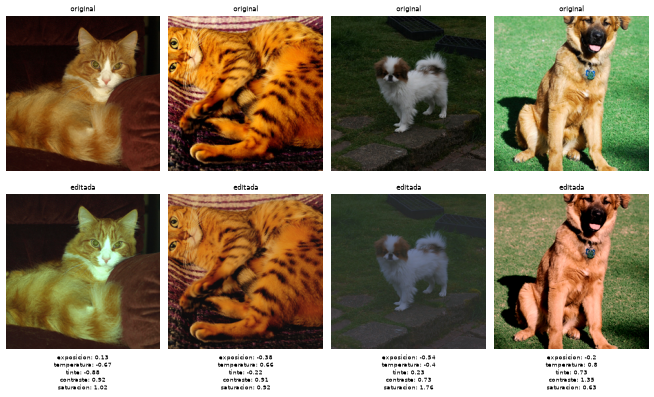

In [7]:
fig, ejes = plt.subplots(2, 4, figsize=(12, 7.5))
for col, f in enumerate(filas[:4]):
    ejes[0, col].imshow(es.abrir(trabajo, f['original']))
    ejes[0, col].set_title('original', fontsize=9)
    ejes[1, col].imshow(es.abrir(trabajo, f['editada']))
    ejes[1, col].set_title('editada', fontsize=9)
    ejes[1, col].text(0.5, -0.03, '\n'.join(f'{k}: {v}' for k, v in f['ajustes'].items()),
                      transform=ejes[1, col].transAxes, ha='center', va='top', fontsize=8)
for e in ejes.ravel():
    e.axis('off')
plt.tight_layout()
es.guardar_figura(raiz / 'img' / '01_antes_despues.png')
plt.show()

## 7. Tu turno: ¿qué pasaría si...?

Cambia los valores de la celda siguiente y vuelve a ejecutarla (no toca las parejas guardadas). Después piensa en las preguntas de debajo.

- ¿Y si pones `saturacion=0` (blanco y negro) y varías `temperatura`? ¿Se nota el cambio de temperatura en la foto resultante?
- ¿Y si subes mucho `exposicion` y `contraste` a la vez? ¿Qué ocurre con las zonas claras?
- ¿Y si ejecutaras la sección 4 dos veces con la misma `SEMILLA`? ¿Y con otra? (No lo hagas con tus parejas ya hechas: los notebooks siguientes las leen. Piénsalo antes de probarlo.)

**Pistas.** Con saturación 0 la foto queda en grises: los canales rojo, verde y azul valen lo mismo, así que la temperatura ya no se puede leer de la imagen. Con exposición y contraste altos, las luces llegan al blanco y se recortan: esa información no se recupera. Y con la misma semilla salen siempre las mismas parejas; con otra, otras.

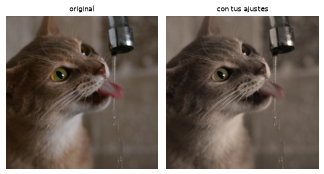

Tus ajustes: {"exposicion": 0.0, "temperatura": 0.8, "tinte": 0.0, "contraste": 1.0, "saturacion": 0.4}


In [8]:
mio = dict(es.NEUTRO, temperatura=0.8, saturacion=0.4)   # cambia estos valores y vuelve a ejecutar
fig, ejes = plt.subplots(1, 2, figsize=(6, 3.2))
ejes[0].imshow(foto)
ejes[0].set_title('original', fontsize=9)
ejes[1].imshow(es.aplicar_ajustes(foto, mio))
ejes[1].set_title('con tus ajustes', fontsize=9)
for e in ejes:
    e.axis('off')
plt.tight_layout()
plt.show()
print('Tus ajustes:', es.a_json(mio))

## Si falla

| Síntoma | Qué probar |
|---|---|
| La descarga de las fotos (791,9 MB) es lenta o se corta | Descarga `images.tar.gz` por tu cuenta desde la página de Oxford-IIIT Pet y define `ESTILO_TAR` con su ruta |
| Cambias `N_EJEMPLOS` a un número **menor** que uno anterior y salen solo gatos | La carpeta `fotos_<resolución>` guarda las fotos ya extraídas y se lee en orden alfabético (los gatos, primero). Borra esa carpeta, o usa otra carpeta de trabajo, y vuelve a ejecutar |
| `ModuleNotFoundError: estilo` | Abre el notebook desde dentro de la carpeta del extra, o define `ESTILO_EXTRA` con su ruta |

## Qué te llevas

- **Fabricar datos** da etiquetas exactas y gratis, porque conocemos el proceso que los genera. A cambio, los datos son artificiales: hay que preguntarse si se parecen a los que verá el modelo de verdad.
- Una etiqueta fabricada debe poder **verificarse**: aquí, aplicar el JSON a la original reproduce la editada.
- El reparto **train / val / test** se hace por foto y con **semilla**, para que el examen sea honesto y el resultado se pueda repetir.
- En el notebook 02 preguntaremos al LLM de visión sin enseñarle nada; en el 03, con LoRA; en el 04, sabremos si hacía falta.

## Para pensar

1. ¿Por qué repartimos por **foto** y no por pareja? ¿Qué pasaría con la medida final si la misma foto estuviera en *train* y en *test* con ajustes distintos?
2. Los ajustes se sortean de forma uniforme en su rango. Si en tus fotos reales casi nunca se usara una saturación de 0,2, ¿qué problema tendría entrenar con datos fabricados así?